# 제2교시. 실제 GPT-2로 읽는 Transformer → GPT 구조

## 이번 교시의 목표

- 실제 GPT-2 설정과 가중치의 블록·헤드·표현 크기를 연결합니다.
- 어텐션 행렬에서 미래 위치 마스킹을 확인합니다.
- 마지막 입력 토큰을 바꾼 대조 결과로 인과적 정보 흐름을 설명합니다.

## 이번 교시 핵심 용어

- **쿼리(Query, Q)·키(Key, K)·값(Value, V):** Q는 찾을 정보의 단서, K는 비교할 단서, V는 섞어 전달할 정보입니다.
- **셀프 어텐션(self-attention):** 같은 시퀀스에서 Q·K·V를 만들어 위치 사이의 정보를 참고합니다.
- **크로스 어텐션(cross-attention):** 한 시퀀스에서 만든 Q로 다른 시퀀스의 K·V를 참고합니다. 원래 Transformer 디코더는 이 경로로 인코더 출력을 읽습니다.
- **인과적 셀프 어텐션(causal self-attention):** 같은 시퀀스의 **현재 위치와 앞선 토큰만 참고하고, 뒤 토큰은 가립니다.** 여기서 ‘인과적’은 사건의 원인·결과를 추론한다는 뜻이 아니라 미래 위치를 미리 읽지 않는다는 뜻입니다.
- **미래 토큰을 가리는 마스크(causal mask):** 어텐션 계산에서 뒤쪽 위치를 참고하지 못하게 하는 제한입니다. 그림에서는 짧게 **‘미래 토큰 가리기’**로 표시합니다.
- **잔차 연결(residual connection):** 입력을 우회시켜 변환 결과에 더하는 경로입니다.
- **사전 정규화(Pre-LayerNorm, Pre-LN):** 어텐션·FFN 같은 변환 앞에서 정규화하는 배치입니다.

## 실습 준비

**시작 조건:** 제1교시에서 준비한 Windows 11 프로젝트의 `.venv\Scripts\python.exe`를 VS Code Notebook 커널로 선택합니다. 수업용 PyTorch·Transformers가 설치되어 있고 NVIDIA CUDA 장치를 사용할 수 있어야 합니다. CUDA 검사가 실패하면 다음 셀로 넘어가지 말고 커널 선택·드라이버·패키지 설치 상태를 확인합니다.

**필요 파일과 실행 순서:** 이 Notebook의 코드가 `openai-community/gpt2`의 약 548 MB 학습 가중치와 설정·토크나이저를 자동으로 읽습니다. 최초 다운로드에는 인터넷이 필요하며 같은 캐시에서는 재사용합니다. 모델 파일이나 버전 ID를 직접 입력할 필요는 없습니다. 앞 교시의 Python 변수에 의존하지 않으며, 이 파일의 코드 셀은 위에서부터 순서대로 실행합니다. 다운로드 오류가 발생하면 해당 셀의 오류를 보존하고 연결 상태를 확인한 뒤 그 단계부터 다시 진행합니다.

**결과 확인:** 개념과 그림 → 코드 설명 → 코드·저장 출력 → 출력 설명 순서로 살펴봅니다. 저장된 출력은 이전 실행 기록입니다. 현재 실행의 오류나 미실행 상태를 이전 `[PASS]`로 대신하지 않습니다. 커널·런타임을 재시작하면 변수들이 없어지므로 처음부터 실행합니다.

제1교시 프로젝트 `.venv` 커널을 선택합니다. 최초 실행에는 인터넷과 모델 가중치 약 **548 MB** 및 토크나이저 파일의 다운로드가 필요합니다. 캐시가 있으면 재사용합니다. 새 패키지는 설치하지 않습니다. 생성문 품질 평가나 문장 생성은 하지 않습니다.

### 학습 범위
실제 공개 모델 **openai-community/gpt2**의 설정과 학습된 가중치를 그대로 사용합니다. 블록·헤드·표현 차원·어휘를 축소하지 않습니다. 짧은 문장은 관찰하기 쉽도록 입력만 짧게 만든 것이며 모델 크기를 줄인 것이 아닙니다.




원래 Transformer는 [2017년 논문](https://arxiv.org/abs/1706.03762)에서 제안됐습니다. 그 뒤 OpenAI는 [2018년 6월 11일 GPT](https://openai.com/index/language-unsupervised/)를, [2019년 2월 14일 GPT-2](https://openai.com/index/better-language-models/)를 소개했습니다. 이 실습에서 쓰는 **124M 기본형**은 GPT-2 발표 때 공개된 소형 모델이며, 이후 공개된 1.5B 모델과는 다릅니다.

이 실습은 검증한 GPT-2 버전을 자동으로 불러옵니다. 버전 ID를 직접 입력할 필요는 없습니다.


## 1. 먼저 정보의 흐름을 그려 보기


### 개념 먼저: 같은 모델을 다시 관찰하려면

모델 이름만 같아도 저장소 파일이나 실행 환경은 바뀔 수 있습니다. 실습은 모델의 파일 버전을 고정하고 현재 Python·라이브러리·장치를 확인합니다. 이 준비는 구조 관찰의 재현 조건이지 생성 품질 검사는 아닙니다.

구조를 비교할 때 모델 파일까지 바뀌면 결과 차이가 코드 때문인지 모델 때문인지 알기 어렵습니다. revision은 저장소의 특정 시점을 지정하는 표식입니다. 이번 준비에서는 모델의 정답률이 아니라, 뒤의 관찰에서 같은 대상을 사용한다는 조건을 확보합니다.


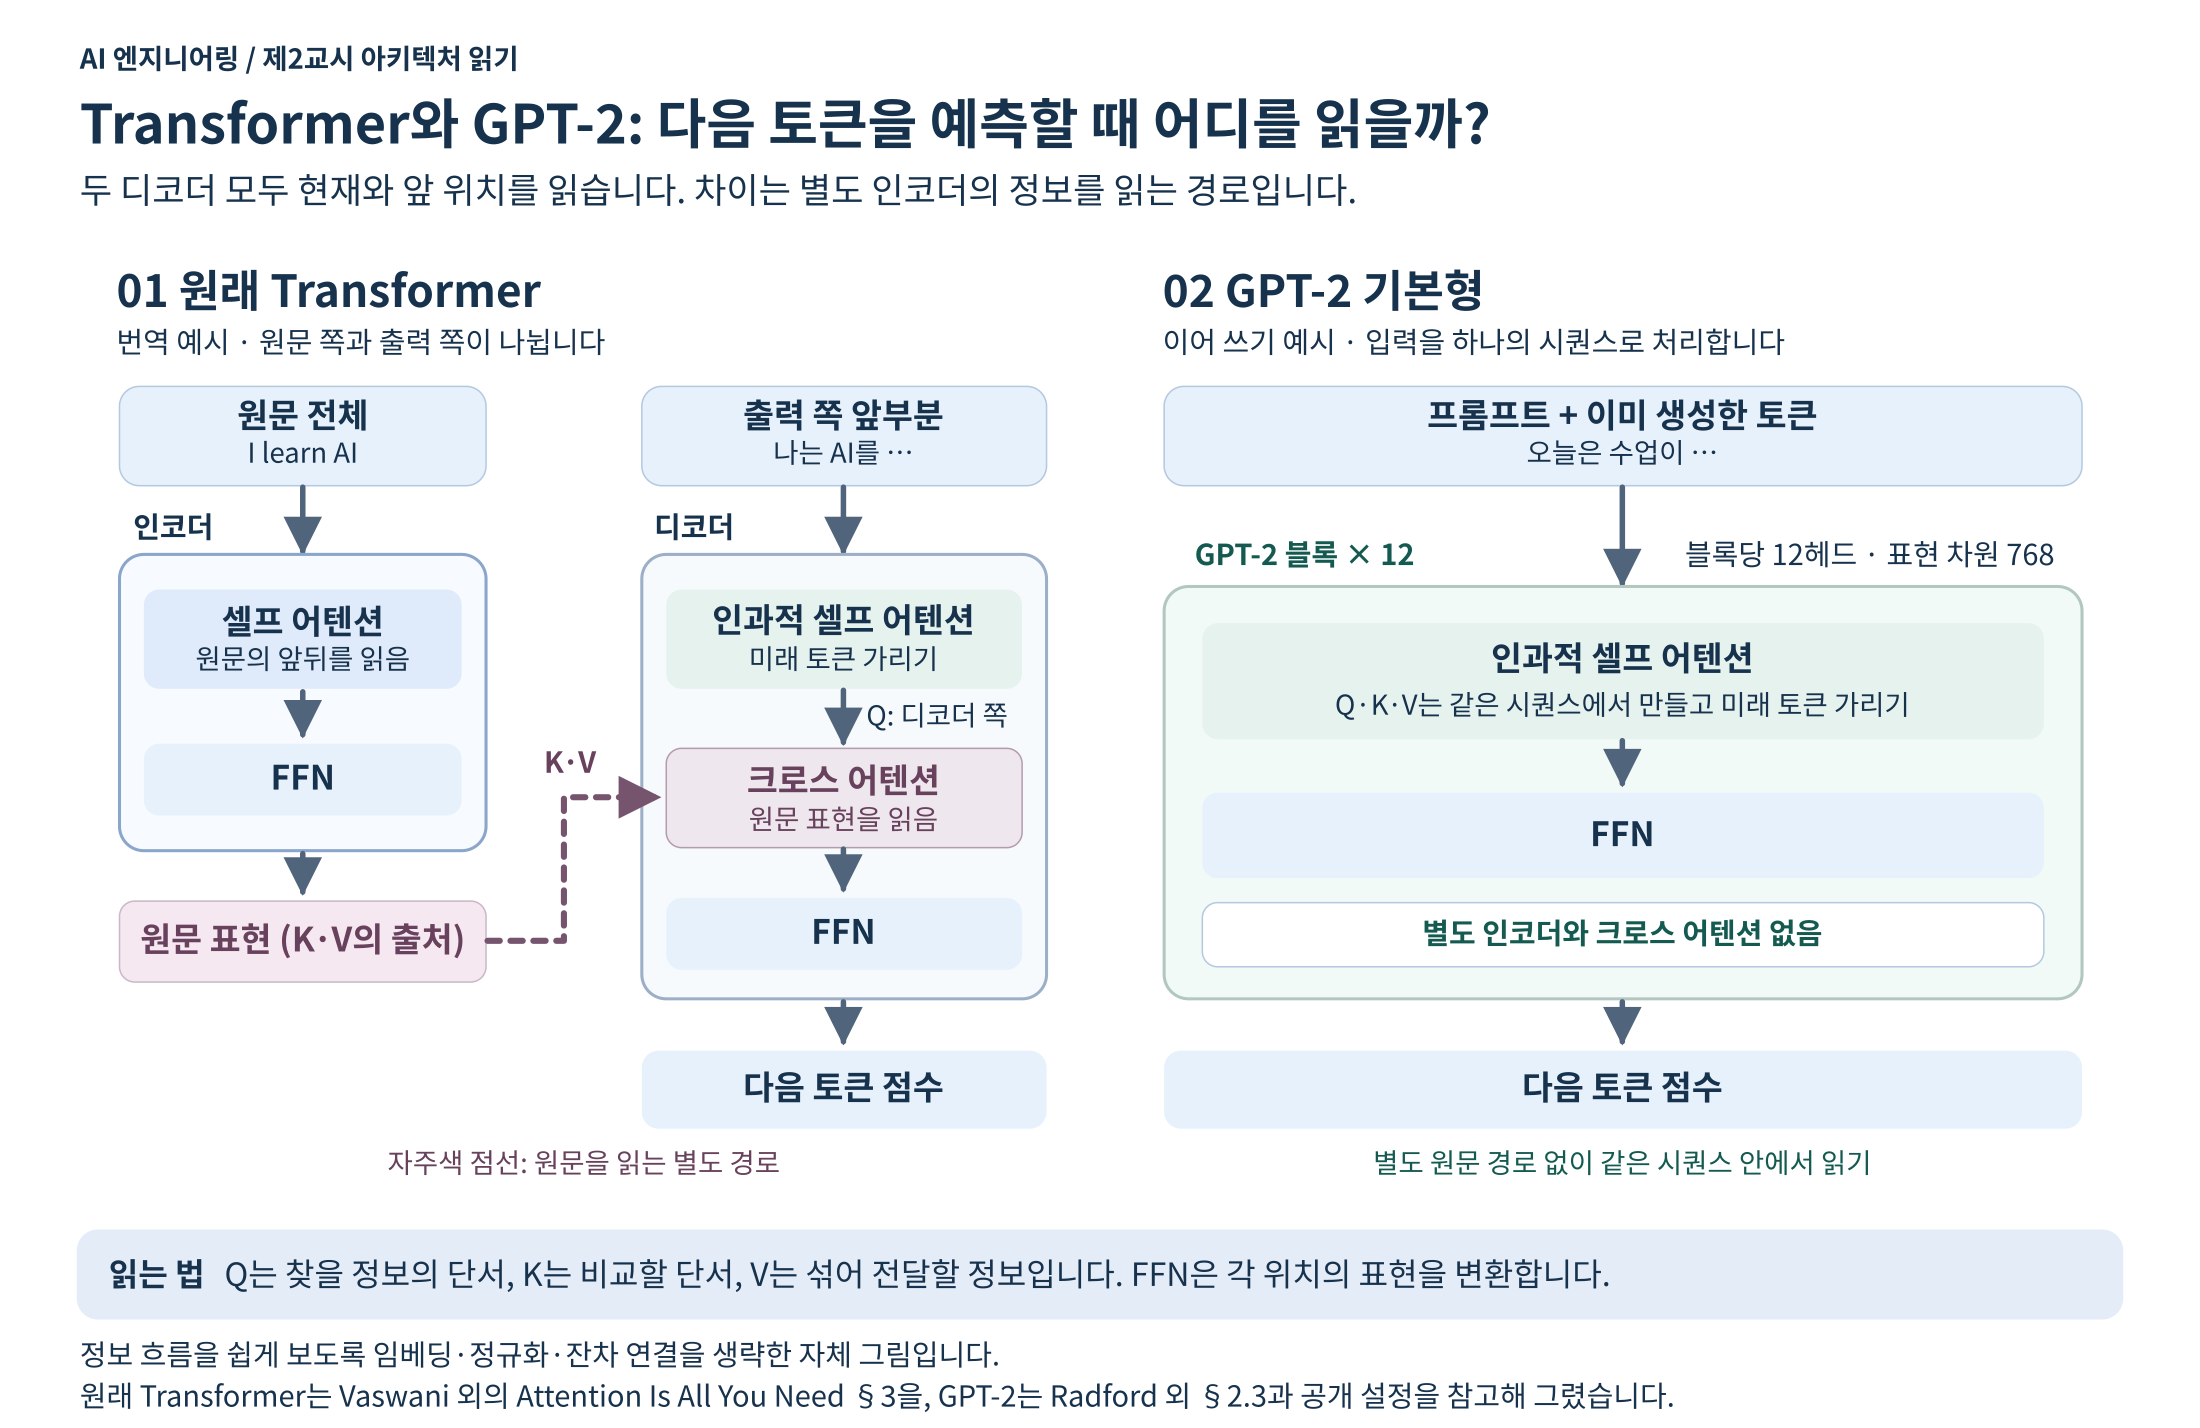

### 논문의 ‘층(layer)’과 코드의 ‘블록(block)’은 어떻게 연결되나요?

원래 Transformer 그림에서 **같은 모양의 큰 상자가 여러 번 쌓인 것**을 떠올려 보세요. 이 수업에서는 그 상자 하나, 즉 입력 표현을 한 번 받아 다음 표현으로 바꾸는 반복 단위를 **블록**이라고 부릅니다. ‘어텐션 층’처럼 층이라는 말은 더 작은 연산에도 쓰이므로, 여기서는 **블록 = 반복 단위 하나**, **서브층 = 그 안의 개별 변환(어텐션 또는 FFN 등)**으로 구분합니다. 블록마다 구조는 같지만 가중치는 따로 학습됩니다.

| 눈여겨볼 것 | 원래 Transformer (2017) | GPT-2 (2019, 실습 모델) |
|---|---|---|
| 모델에 주어진 문제 | 원문을 조건으로 번역문의 다음 토큰 예측 | 한 토큰 시퀀스의 앞부분을 조건으로 다음 토큰 예측 |
| 블록을 쌓는 방식 | 인코더 6개와 디코더 6개를 별도로 쌓음 | 한 종류의 블록 12개를 쌓음. 12는 실습 체크포인트의 크기이며 GPT-2 계열 전체에 고정된 수가 아님 |
| 디코더 쪽 블록 안의 변환 | 인과적 셀프 어텐션 → 크로스 어텐션 → FFN | 인과적 셀프 어텐션 → FFN(코드에서 `mlp`) |
| LayerNorm과 잔차의 순서 | 서브층 계산 → 입력을 더함 → LayerNorm | LayerNorm → 서브층 계산 → 정규화 전 입력을 더함. 전체 블록 뒤에는 별도 `ln_f` |
| 위치 표현 | 사인·코사인으로 계산하는 위치 표현을 기본으로 사용 | 학습된 절대 위치 임베딩을 사용. 3교시에서 실제 텐서로 확인 |

**왜 별도 인코더와 크로스 어텐션을 쓰지 않을까요?** 번역 모델은 이미 주어진 원문과 지금까지의 번역을 **두 흐름**으로 구분합니다. 디코더의 크로스 어텐션은 그 두 흐름을 이어 줍니다. GPT-2는 프롬프트와 이어서 생성하는 토큰을 **한 흐름**에 놓습니다. 각 위치는 같은 시퀀스에서 현재와 앞 위치를 참고하므로, 다음 토큰을 예측하는 데 별도 인코더 출력이 필요하지 않습니다. GPT-2가 조건 없이 생성한다는 뜻은 아닙니다. **조건인 프롬프트가 같은 흐름의 앞부분**에 있습니다. 잔차, FFN, 멀티헤드 셀프 어텐션은 버린 것이 아니라 그대로 이어받은 요소입니다.

이 선택은 처음부터 GPT-2가 새로 만든 것이 아니라 앞선 [GPT 구조](https://cdn.openai.com/research-covers/language-unsupervised/language_understanding_paper.pdf)를 이어받은 것입니다. 따라서 GPT-2를 **‘원래 Transformer의 디코더를 그대로 떼어 낸 것’**이라고 보면 크로스 어텐션의 부재와 정규화 순서의 차이를 놓칩니다.

**3교시 미리 보기:** 원래 Transformer와 GPT-2는 모두 토큰 벡터에 위치 정보를 더하지만, 원래 Transformer의 기본 모델은 사인·코사인 공식으로 계산하고 GPT-2는 학습된 위치 벡터를 꺼냅니다. 이 차이는 3교시 임베딩 실습에서 확인합니다.

그림에서 정규화·잔차 연결 등은 생략했습니다. **Q**는 이 위치가 어떤 정보를 찾는지, **K**는 다른 위치와 얼마나 잘 맞는지 비교할 단서, **V**는 실제로 전달할 정보입니다. Q와 K로 읽을 비중을 정한 뒤 V를 섞습니다. 사람이 읽는 질문 문장이 Q에 직접 저장된다는 뜻은 아닙니다.

| 구조 | Q | K·V | 읽을 수 있는 위치 |
|---|---|---|---|
| 인코더 셀프 어텐션 | 원문 측 | 같은 원문 측 | 이 예에서는 전체 원문 |
| 디코더 인과적 셀프 어텐션 | 출력 측 | 같은 출력 측 | 현재와 이전 위치 |
| 원래 디코더의 크로스 어텐션 | 디코더 측 | 인코더 출력 | 전체 유효 원문 |
| 기본 GPT-2의 셀프 어텐션 | 하나의 시퀀스 | 같은 시퀀스 | 현재와 이전 위치 |

“나는 / 학교에 / 간다”에서 ‘학교에’가 다음 단어를 예측한다면 ‘간다’를 미리 읽으면 안 됩니다. 아래 단어 구분은 설명용이며 실제 토크나이저 경계가 아닙니다.

| 읽는 위치 ↓ / 참고 위치 → | 나는 | 학교에 | 간다 |
|---|---|---|---|
| 나는 | ○ | × | × |
| 학교에 | ○ | ○ | × |
| 간다 | ○ | ○ | ○ |

현재 입력을 보고 **다음** 토큰을 예측하므로 대각선은 허용합니다. 마스크는 대각선 위쪽의 미래 위치를 차단합니다.

원래 Transformer의 인코더·디코더 구조와 어텐션 연결은 Vaswani 외의 [Attention Is All You Need](https://arxiv.org/abs/1706.03762), 그림 1·§3.1·§3.2.3에 설명되어 있습니다. GPT의 디코더 기반 구조는 [GPT 기술 보고서](https://cdn.openai.com/research-covers/language-unsupervised/language_understanding_paper.pdf) §3.1, GPT-2의 정규화 변경은 [GPT-2 기술 보고서](https://cdn.openai.com/better-language-models/language_models_are_unsupervised_multitask_learners.pdf) §2.3을 확인합니다. 원래 디코더를 수정 없이 그대로 떼어 낸 구조라고 설명하지 않습니다.

### 코드 설명: 같은 GPT-2를 관찰하기 위한 준비

이 셀은 실행 환경을 확인하고 동일한 GPT-2 버전과 계산 장치를 지정합니다. 아직 가중치 다운로드나 문장 계산은 하지 않습니다. 모델 구조와 계산 결과를 비교하려면 먼저 어떤 환경·파일을 사용하는지 고정해야 합니다.

실행하면 현재 노트북이 사용하는 Python과 라이브러리 버전, CUDA 장치가 표시됩니다. 이 정보는 다음 셀들이 의도한 환경에서 실행되는지 판단하는 기준입니다.


In [21]:
import os, sys, platform, json, hashlib
import torch
import transformers
from huggingface_hub import hf_hub_download
from transformers import GPT2Config, GPT2LMHeadModel, GPT2TokenizerFast

# 현재 커널이 읽은 Python 정보입니다. 설치 명령을 실행한 다른 환경과 구분합니다.
print("Python:", sys.executable)
print("OS:", platform.system())
print("torch:", torch.__version__, "transformers:", transformers.__version__)
assert platform.system() == "Windows", "Windows 11에서 실습을 실행하세요."
# CUDA 조건이 맞지 않으면 모델을 받기 전에 중단합니다.
assert torch.cuda.is_available(), "제1교시 CUDA 검사와 Notebook 커널을 확인하세요."
# 장치 지정만 준비합니다. 텐서·모델의 실제 이동은 생성 옵션 또는 to(device)가 수행합니다.
device = torch.device("cuda:0")
# 모델 이름과 revision을 함께 고정해 실습 대상이 바뀌지 않게 합니다.
MODEL_ID = "openai-community/gpt2"
REVISION = "607a30d783dfa663caf39e06633721c8d4cfcd7e"
print("GPU:", torch.cuda.get_device_name(0))
print("[PASS] 실제 GPT-2 실행 환경")


Python: %USERPROFILE%\AI-Engineering\modern-llm-vlm-architecture\.venv\Scripts\python.exe
OS: Windows
torch: 2.9.1+cu126 transformers: 5.23.0
GPU: NVIDIA GeForce RTX 4090
[PASS] 실제 GPT-2 실행 환경


### 출력 설명: 실행 기록과 확인 범위

- 실행 파일 경로는 현재 노트북이 어느 Python을 사용했는지 보여 줍니다. 과정 가상환경의 `.venv\Scripts\python.exe`와 Windows가 기록되어 있으며, GPU는 NVIDIA GeForce RTX 4090입니다. 설치한 환경과 노트북 커널이 연결되어 있는지 이 조합으로 확인합니다.
- PASS는 운영체제와 CUDA 등 이 셀의 환경 검사를 통과하고 모델 식별자·revision을 준비했다는 뜻입니다. 아직 설정 파일의 내용이나 실제 가중치를 검사한 단계는 아닙니다.


## 2. 실제 공개 config 읽기

[고정 revision의 GPT-2 `config.json`](https://huggingface.co/openai-community/gpt2/blob/607a30d783dfa663caf39e06633721c8d4cfcd7e/config.json)만 먼저 받아 실제 파일을 읽습니다. 캐시에 있으면 같은 파일을 사용합니다. 해시 검사는 수업에서 확인한 원문과 바이트가 같은지 확인합니다.

| 항목 | 뜻 | 실제 실행에서 확인한 값 |
|---|---|---|
| architectures | 모델 구현 클래스 | GPT2LMHeadModel |
| n_layer | 반복 블록 수 | 12 |
| n_head | 블록당 어텐션 헤드 수 | 12 |
| n_embd | 위치별 표현 차원 | 768 |
| n_positions | 위치 임베딩 개수 | 1024 |
| vocab_size | 어휘 ID 수 | 50257 |

헤드당 차원은 `768 ÷ 12 = 64`입니다. 

**다음 단계:** 설정값은 모델의 크기를 알려 줍니다. 3절의 실제 가중치 로드 출력 바로 아래 도식에서 블록 내부의 계산 순서와 잔차 연결을 확인합니다.


### 개념 먼저: 구조의 숫자를 축과 연결하기

블록 수는 표현을 갱신하는 반복 횟수이고, 표현 폭은 토큰 하나를 나타내는 숫자의 개수입니다. 어휘 수는 선택 가능한 토큰 번호의 범위입니다. 설정을 먼저 읽으면 뒤에서 나온 텐서 크기를 외우는 대신 각 축이 왜 필요한지 연결할 수 있습니다.

문장 하나의 토큰이 6개라면 위치마다 768개 숫자로 표현하되, 출력 단계에서는 위치마다 50,257개 후보 점수가 필요합니다. 그래서 입력 길이·표현 폭·어휘 크기는 서로 바꿔 쓸 수 없습니다. 아래 설정값을 읽고 뒤에서 가중치 표의 크기와 실제 출력 축에 각각 대응시킵니다.


### 코드 설명: 설정 파일은 구조의 설계도

설정 파일은 블록 수·표현 폭·어휘 크기 같은 구조의 설계도입니다. 파일의 동일성과 구조 값을 확인한 뒤 다음 셀에서 실제 가중치와 대조합니다. 설정을 읽은 것과 문장 추론에 성공한 것을 구분합니다.

먼저 파일의 SHA-256 지문을 대조해 정해 둔 원본인지 확인합니다. 그런 다음 블록 수, 헤드 수, 표현 폭을 각각 출력하고, 표현 폭을 헤드 수로 나눠 헤드 하나의 차원을 확인합니다.


In [22]:
from pathlib import Path
# 허브에서 파일 경로를 받습니다. 이미 캐시에 있으면 재사용합니다.
config_path = hf_hub_download(MODEL_ID, "config.json", revision=REVISION)
# 원본 바이트로 지문을 검사하므로 JSON을 다시 저장한 파일과 혼동하지 않습니다.
raw = Path(config_path).read_bytes()
# 내용 지문으로 파일 동일성을 검사하며 모델 성능을 평가하는 것은 아닙니다.
assert hashlib.sha256(raw).hexdigest() == "0daed7749b4f02b8f76240d5444551d7b08712dab4d0adb8239c56ba823bb7b4"
# 이 변수에는 가중치가 아니라 JSON 설정 딕셔너리가 들어갑니다.
checkpoint = json.loads(raw)
for key in ("architectures", "n_layer", "n_head", "n_embd", "n_positions", "vocab_size"):
    print(f"{key}: {checkpoint[key]}")
# 설정 항목을 같은 순서의 기준값과 대조합니다. 숫자 순서를 바꾸면 의미가 달라집니다.
assert (checkpoint["n_layer"], checkpoint["n_head"], checkpoint["n_embd"], checkpoint["n_positions"], checkpoint["vocab_size"]) == (12, 12, 768, 1024, 50257)
assert checkpoint["architectures"] == ["GPT2LMHeadModel"]
print("원본에 add_cross_attention 키 존재:", "add_cross_attention" in checkpoint)
print("헤드당 차원:", checkpoint["n_embd"] // checkpoint["n_head"])
print("[PASS] 실제 GPT-2 config 확인")


architectures: ['GPT2LMHeadModel']
n_layer: 12
n_head: 12
n_embd: 768
n_positions: 1024
vocab_size: 50257
원본에 add_cross_attention 키 존재: False
헤드당 차원: 64
[PASS] 실제 GPT-2 config 확인


### 출력 설명: 실행 기록과 확인 범위

- 12개 블록은 깊이, 768은 위치마다 유지하는 표현의 폭, 12개 헤드는 한 블록 안에서 나누어 계산하는 수입니다. 출력된 헤드당 64는 768을 12로 나눈 값입니다.
- 1,024는 설정된 위치 임베딩의 범위이고, 50,257은 선택할 수 있는 토큰 ID의 개수입니다. 이번 문장의 길이나 생성된 단어 수가 아닙니다. `GPT2LMHeadModel`은 다음 토큰 점수를 내는 출력층까지 포함하는 모델 종류입니다.
- PASS는 원본 파일의 SHA-256 지문과 지정한 구조 값이 모두 맞았다는 뜻입니다. `키 존재: False`라는 출력은 JSON의 항목 유무 검사 결과이며, 실제 모듈 구성은 다음 셀에서 확인합니다.


## 3. 실제 학습 가중치 로드 및 블록 확인

**언어 모델 출력층(language model head, LM Head)**은 블록이 만든 표현을 다음 토큰 후보의 점수로 바꾸는 마지막 층입니다. 어텐션의 여러 헤드와는 역할이 다릅니다.

**최초 실행에는 약 548 MB의 safetensors 가중치와 토크나이저 파일을 받습니다.** 완료될 때까지 기다립니다. 이전 실행의 캐시를 재사용하므로 매번 같은 용량을 다시 받는 것은 아닙니다. 네트워크 오류가 나면 이 셀을 완료하기 전까지 다음 셀로 넘어가지 않습니다.

`from_pretrained`로 학습된 가중치를 불러옵니다. 무작위 초기화, meta 장치, 블록 수 축소는 사용하지 않습니다. `eager`는 어텐션 행렬을 읽기 위한 구현 선택이며 모델 크기나 학습 가중치를 바꾸지 않습니다. `eval()`로 dropout을 끄고 비교합니다. 이번 시간에는 KV 캐시 없이 forward를 수행합니다.



### 왜 목록에 잔차 연결이 없을까요?

`['ln_1', 'attn', 'ln_2', 'mlp']`는 `named_children()`이 보여 준 **등록 하위 모듈 목록**입니다. ‘첫 블록 구성’이라는 출력 이름이 전체 실행 순서를 뜻하는 것은 아닙니다. 잔차 연결은 모듈이 아니라 계산 도중에 **입력 텐서를 결과에 더하는 `+` 연산**이라서 이 목록에 나오지 않습니다.

마스크 등의 인자를 생략하면 첫 블록의 계산 순서는 다음과 같습니다.

```text
h = x + attn(ln_1(x))   # 어텐션 앞에서 정규화하고, 그 전 입력 x를 더함
y = h + mlp(ln_2(h))    # MLP 앞에서 정규화하고, 그 전 입력 h를 더함
```

| 같은 서브층을 비교하면 | 계산 규칙 |
|---|---|
| 원래 Transformer: **Post-LayerNorm** | `LayerNorm(x + F(x))` : 잔차를 더한 뒤 전체를 정규화 |
| GPT-2: **Pre-LayerNorm** | `x + F(LayerNorm(x))` : 변환 경로만 먼저 정규화하고 우회한 입력을 더함 |

여기서 `F`는 한 서브층의 변환입니다. **두 방식 모두 잔차 연결이 있습니다.** 차이는 **우회한 입력에도 해당 서브층의 정규화가 적용되는가**입니다. GPT-2의 `ln_f`는 12개 블록을 모두 통과한 뒤 LM Head 직전에 적용되는 별도 정규화입니다. 블록 안의 `ln_1`·`ln_2`와 구분하세요.

**왜 정규화를 앞에 놓았을까요?** 그림에서 입력 `x`가 두 갈래로 나뉘는 부분을 보세요. 한쪽은 계층 정규화(LayerNorm)를 거쳐 어텐션으로 들어갑니다. 다른 쪽은 정규화를 거치지 않고 그대로 지나가 어텐션 결과에 더해집니다. 이 두 번째 길이 잔차 경로(residual path)입니다.

학습할 때 출력에서 계산한 오차를 바탕으로, 뒤쪽 층부터 기울기를 계산하는 과정을 **역전파(backpropagation)**라고 합니다. 이때 **기울기(gradient)**는 가중치를 어느 방향으로 바꿔야 오차가 줄어드는지 알려 주는 정보입니다. 사전 정규화에서는 기울기의 일부가 직접 잔차 경로를 따라 각 서브층의 정규화를 우회할 수 있습니다. 반대로 덧셈 뒤에 정규화하면, 뒤에서 오는 기울기는 그 정규화를 먼저 거쳐야 합니다.

[GPT-2 보고서 §2.3](https://cdn.openai.com/better-language-models/language_models_are_unsupervised_multitask_learners.pdf#page=4)은 정규화를 서브층 앞으로 옮기고 마지막 계층 정규화를 추가했다고 기록합니다. 이후 [Xiong 외(2020)](https://proceedings.mlr.press/v119/xiong20b.html)는 사전 정규화의 초기 기울기가 더 안정적인 성질을 보이는 이유를 분석했습니다. 이는 학습에 도움이 될 수 있다는 후속 설명이지, GPT-2의 선택 동기를 입증하거나 모든 모델에서 우월함을 보장하는 말은 아닙니다. 이번 실습은 추론만 하므로 학습 안정성을 비교하지 않습니다.

**30초 확인:** 어텐션 결과가 0이라면, GPT-2의 첫 번째 잔차 덧셈 직후에는 무엇이 남을까요? **답:** `x`가 그대로 남습니다. 원래 Transformer의 같은 자리에서는 덧셈 뒤 정규화를 하므로 서브층 최종 출력은 `LayerNorm(x)`입니다. 두 방식의 차이는 식에 숫자를 넣기 전에도 확인할 수 있습니다.

2017년 [Transformer 논문 §3.1](https://arxiv.org/html/1706.03762#S3.SS1)을 보면, 원래 Transformer는 입력에 서브층 결과를 먼저 더한 뒤 정규화합니다.


### 개념 먼저: 모듈 목록과 계산 경로를 구분하기

블록은 어텐션과 MLP 등을 묶어 반복하는 단위입니다. 모듈 목록은 이름표가 붙은 부품 목록이고 forward는 실제 데이터가 지나가는 경로입니다. 잔차 덧셈은 별도 학습 모듈 없이 수행할 수 있으므로 목록에 없더라도 그림의 우회 경로에는 나타납니다.

잔차 연결의 역할은 변환한 값에 원래 표현을 더하여 이전 정보를 직접 전달하는 것입니다. 별도 학습 가중치가 없는 덧셈은 부품 이름 목록에 표시되지 않을 수 있습니다. 따라서 목록만 보고 연결이 없다고 결론 내리지 말고, 그림에서 정규화·어텐션·MLP 사이의 우회선을 함께 따라갑니다. 아래 검사는 실제 부품과 가중치 모양을 확인합니다.


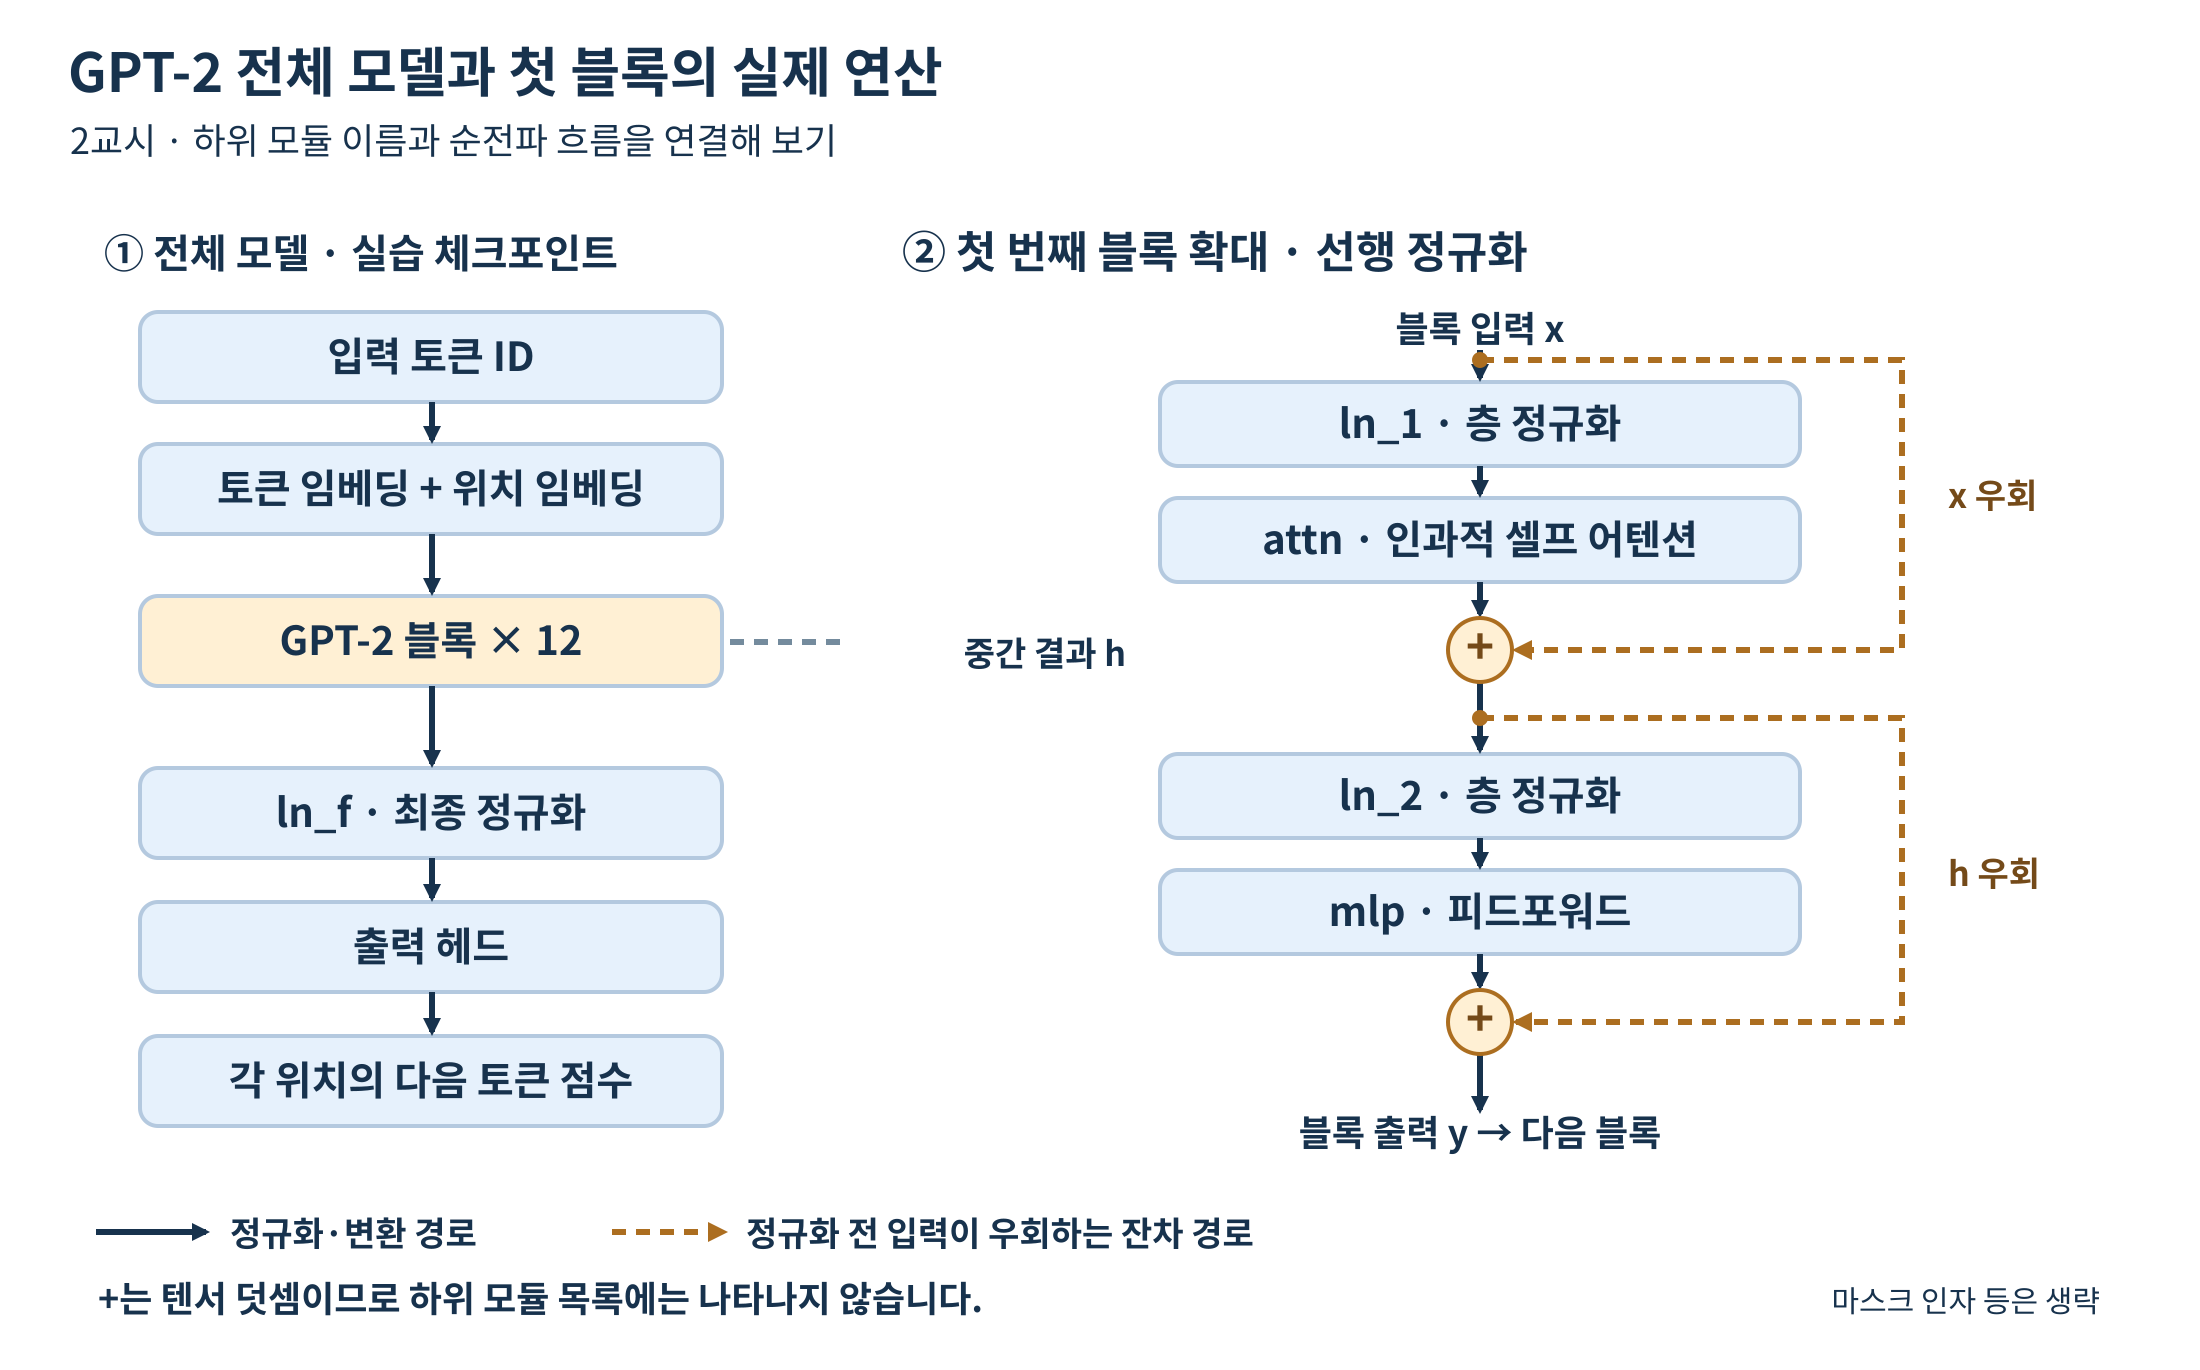

#### 두 선형 변환 사이: ReLU와 GELU

위 그림의 `mlp`는 각 토큰 위치의 특징을 따로 바꾸는 **순방향 신경망(feed-forward network, FFN)**입니다. 두 선형 변환 사이에 **활성화 함수(activation function)**를 넣어, 두 변환을 하나의 선형 변환으로 합칠 수 없게 합니다. [원래 Transformer 논문 §3.3](https://arxiv.org/html/1706.03762#S3.SS3)은 여기서 **ReLU(Rectified Linear Unit)**를 사용했습니다. 실습의 GPT-2 기본형은 **768차원 → 3,072차원 → GELU → 768차원**으로 계산합니다. **GELU(Gaussian Error Linear Unit)**는 중간의 3,072개 값 각각에 적용되며, 적용 전후의 차원 수는 바뀌지 않습니다. [GPT-2 공개 구현](https://github.com/openai/gpt-2/blob/master/src/model.py)에서 이 흐름과 GELU의 `tanh` 근사식을 볼 수 있습니다.

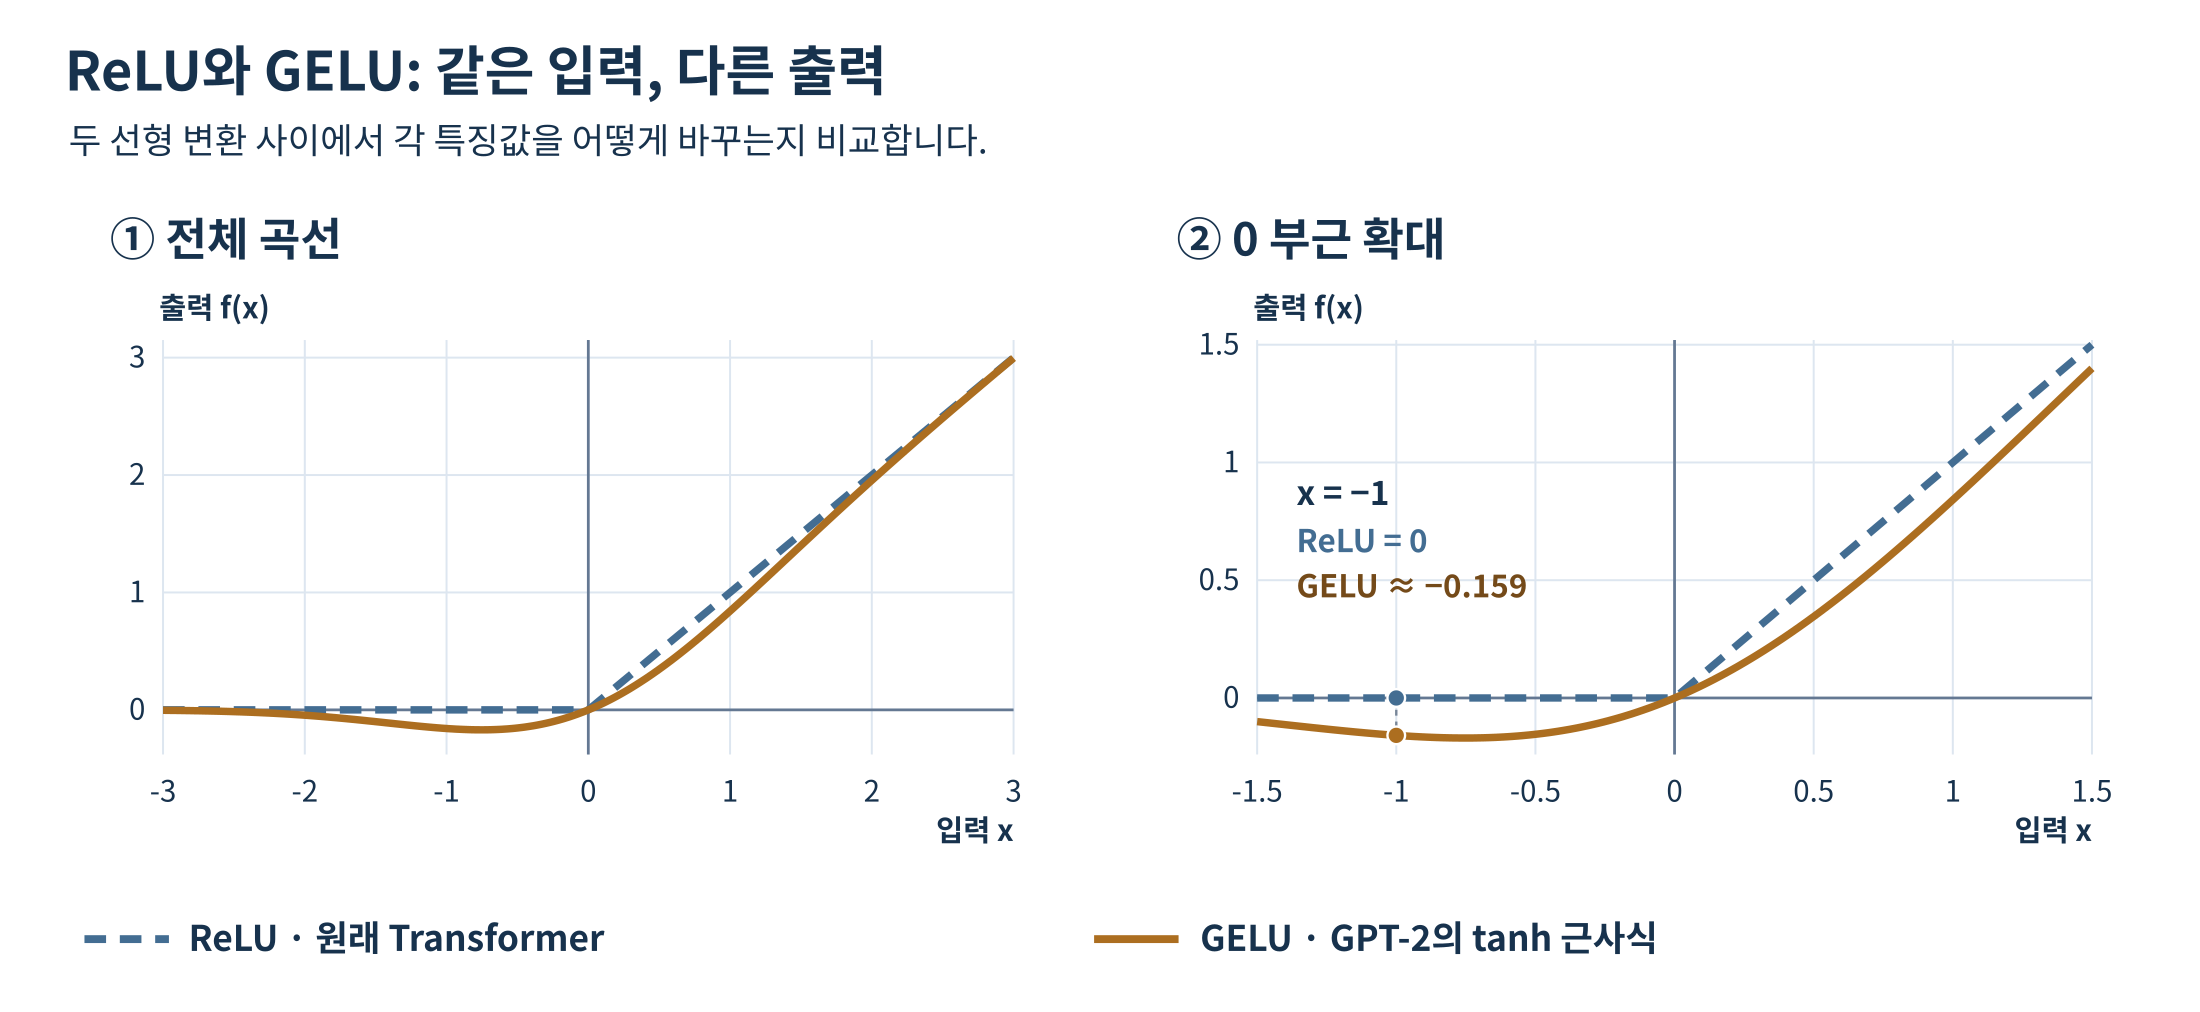

**그림 설명:** 가로축은 활성화 함수에 넣는 특징값 하나, 세로축은 함수가 돌려주는 값입니다. **ReLU**는 음수를 0으로 만들고 양수는 그대로 통과시킵니다. **GELU**는 큰 음수를 0에 가깝게 줄이면서도, 0에 가까운 음수 일부는 작게 남깁니다. 오른쪽 확대 그림처럼 입력이 `−1`이면 ReLU는 `0`, GPT-2의 GELU는 약 `−0.159`입니다. 큰 양수에서는 GELU도 입력을 거의 그대로 통과시킵니다.

이 차이는 **0 부근의 특징값을 어떻게 전달하는가**에 있습니다. GELU가 0 부근에서 부드럽게 변한다는 것은 함수 자체의 성질이지, GPT-2가 더 잘 학습한 이유를 이 비교만으로 입증한다는 뜻은 아닙니다. 그래프는 활성화 함수의 식으로 그렸으며, 아래 실습의 모델 출력과는 별개입니다.

### 그림의 마지막 LM Head는 무엇을 하나요?

12개 블록과 최종 정규화 `ln_f`를 지난 **각 위치의 768차원 표현**을 받아, 어휘 **50,257개 각각이 다음 토큰일 점수인 로짓(logit)**으로 바꿉니다. 어텐션 헤드는 입력 위치 사이에서 정보를 모으는 계산 단위이고, LM Head는 최종 표현을 어휘별 점수로 변환하는 출력층입니다. ‘헤드’라는 이름이 같아도 같은 것이 아닙니다.

위의 `(50257, 768)`은 **저장된 가중치 행렬의 크기**입니다. 50,257개 후보마다 768차원 표현을 점수로 바꾸는 가중치가 있다는 뜻이며, 입력 문장이나 출력값의 크기가 아닙니다. 배치 크기 1, 입력 길이 `T`라면 LM Head의 입력값은 `(1, T, 768)`, 출력값은 `(1, T, 50257)`입니다.

입력 문장 뒤에 새 토큰을 붙일 때는 **마지막 입력 위치의 점수**를 사용합니다. 점수 자체는 확률이 아닙니다. softmax로 확률을 읽고 토큰 하나를 고르는 과정은 3교시에서 다룹니다.



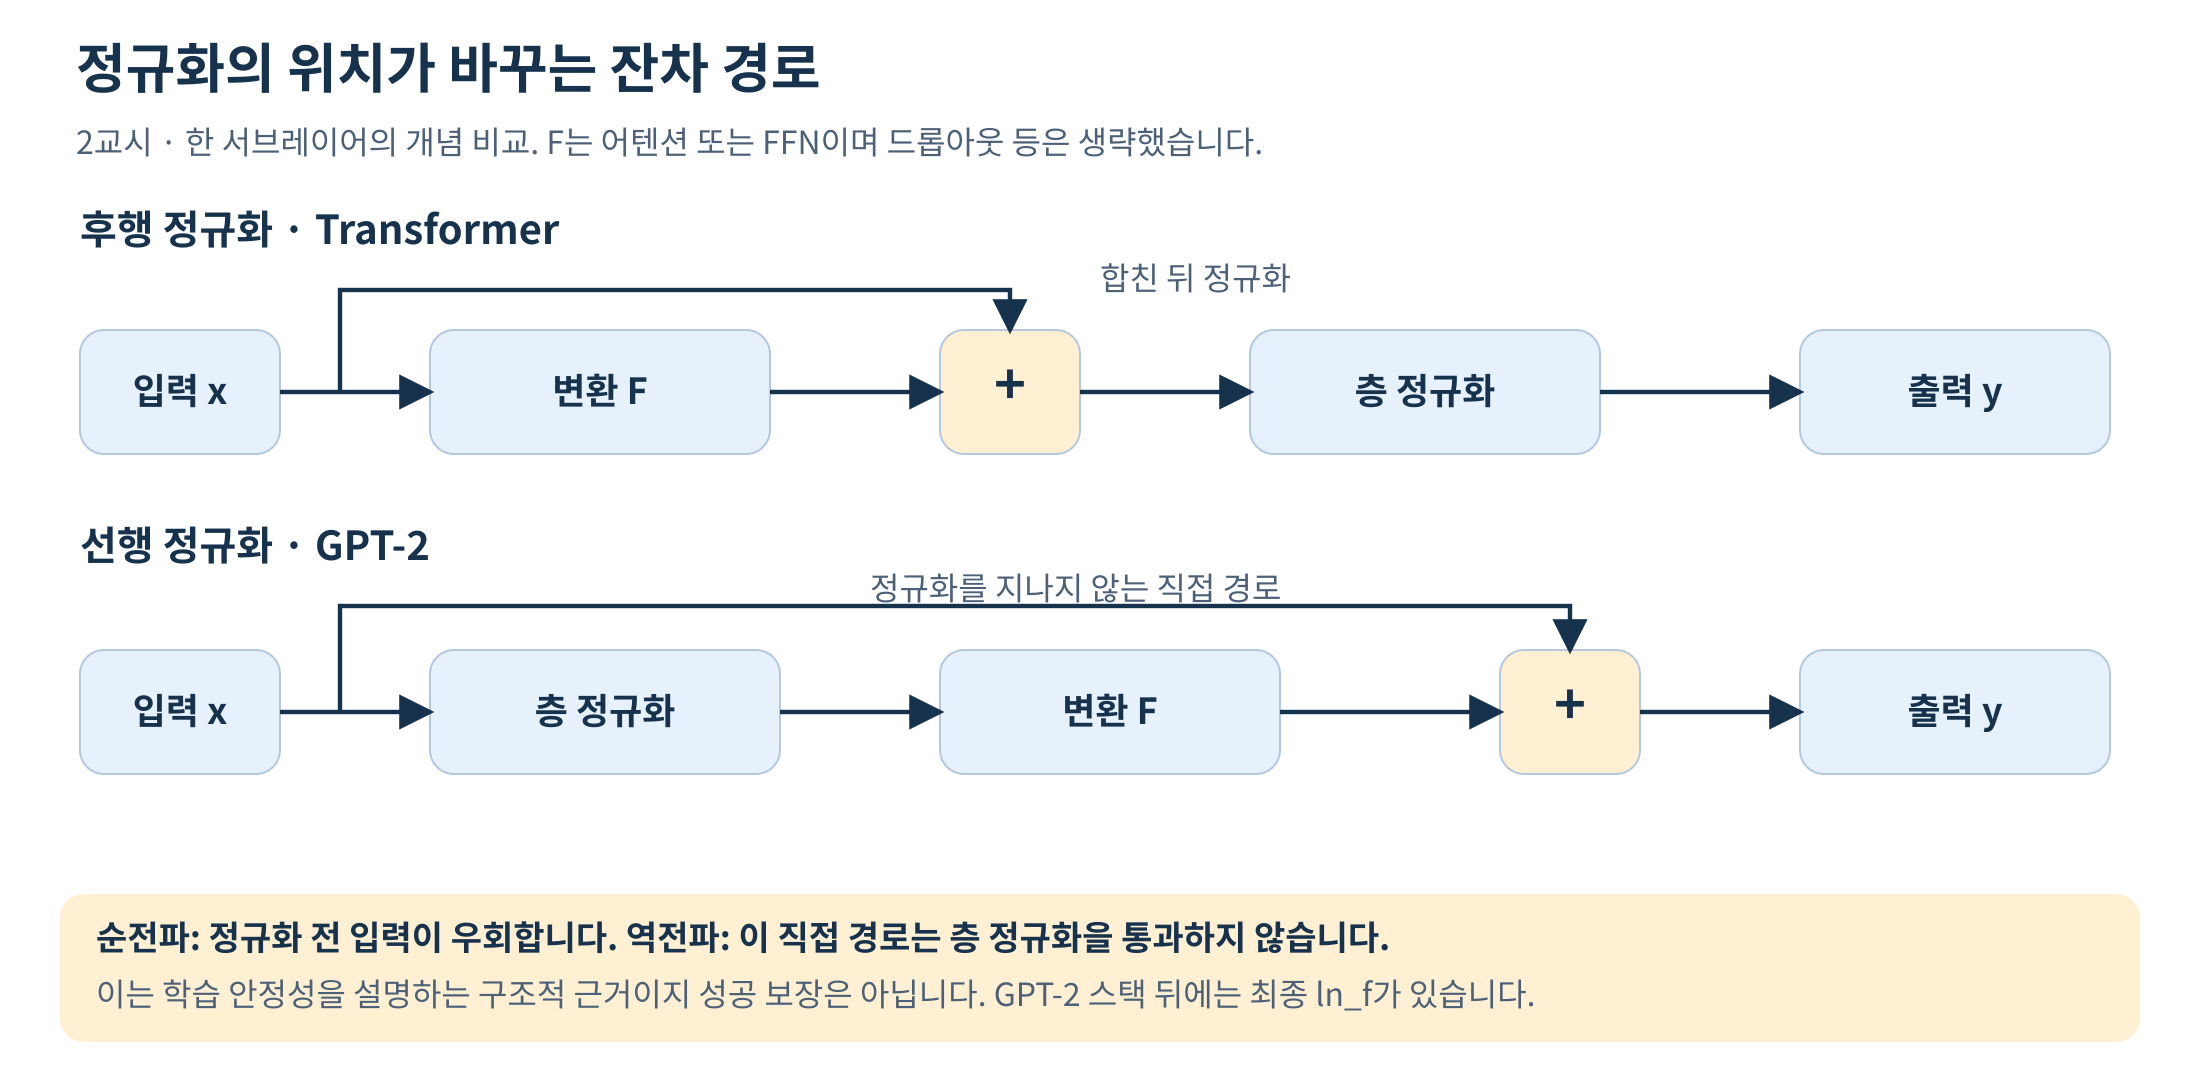

**그림 설명:** 정규화 위치만 분리한 개념도입니다. 아래 코드는 추론 검증이며 이 그림의 역전파 설명을 실험한 것은 아닙니다.


### 코드 설명: 설계도와 학습된 모델을 대조

설정과 같은 버전의 학습 가중치를 읽어 전체 모델을 준비합니다. 토큰·위치 임베딩과 출력층의 모양을 대조하고, 첫 블록의 모듈 이름을 앞의 흐름 그림에 대응시킵니다. 잔차 덧셈은 모듈 목록에 이름이 없어도 실제 계산에 포함됩니다. 가중치 모양과 문장을 넣은 뒤 출력 모양은 서로 다릅니다.

### 같은 어텐션 수식, 다른 실행 방식

`attn_implementation`은 모델의 가중치나 구조가 아니라 **어텐션을 계산할 구현**을 고릅니다.

| 옵션 | 어떻게 계산하나요? | 언제 쓰나요? |
|---|---|---|
| `"eager"` | Q·K 내적과 스케일링, 마스크, 소프트맥스, V 가중합을 단계별로 수행합니다. | 어텐션 가중치 행렬을 직접 관찰할 때 씁니다. 이 교시에서는 나중에 미래 토큰에 준 가중치가 0인지 확인합니다. |
| `"sdpa"` | 같은 계산을 PyTorch의 `scaled_dot_product_attention()`에 맡깁니다. | 가중치 행렬을 따로 읽지 않고 어텐션 출력이 필요할 때 씁니다. 실행 커널은 PyTorch가 고르므로 FlashAttention 실행을 보장하지 않습니다. |

`"eager"`도 수식으로는 **Scaled Dot-Product Attention(SDPA)**을 계산합니다. 소문자 `"sdpa"`는 이 코드에서 **PyTorch 함수에 계산을 맡기라는 옵션값**입니다. [Transformers 구현](https://github.com/huggingface/transformers/blob/v5.23.0/src/transformers/integrations/sdpa_attention.py#L175-L189)


In [23]:
# 토큰 ID와 가중치의 대응을 유지하려고 같은 모델과 revision의 토크나이저를 읽습니다.
tokenizer = GPT2TokenizerFast.from_pretrained(MODEL_ID, revision=REVISION)
# 출력 헤드까지 포함한 학습 가중치를 로드합니다. eval은 기울기 기록을 끄지는 않습니다.
model = GPT2LMHeadModel.from_pretrained(
    MODEL_ID, revision=REVISION, use_safetensors=True,
    # 관찰 가능한 eager 구현과 FP32 계산을 선택합니다. 모델 크기를 줄이지 않습니다.
    attn_implementation="eager", dtype=torch.float32,
).to(device).eval()
print("실제 블록 수:", len(model.transformer.h))
print("토큰 임베딩 shape:", tuple(model.transformer.wte.weight.shape))
print("위치 임베딩 shape:", tuple(model.transformer.wpe.weight.shape))
print("LM Head shape:", tuple(model.lm_head.weight.shape))
# 등록된 자식 모듈 이름만 표시합니다. 잔차 덧셈 같은 연산은 이 목록에 없습니다.
print("첫 블록 구성:", list(dict(model.transformer.h[0].named_children())))
# JSON의 키 존재 여부가 아니라 로드된 모델이 해석한 설정값입니다.
print("해석된 add_cross_attention:", model.config.add_cross_attention)
assert len(model.transformer.h) == 12
assert model.config.n_head == 12 and model.config.n_embd == 768
assert model.transformer.wte.weight.shape == (50257, 768)
assert model.transformer.wpe.weight.shape == (1024, 768)
assert model.lm_head.weight.shape == (50257, 768)
# 해석된 설정을 확인한 뒤 아래에서 실제 모든 블록의 모듈 부재도 검사합니다.
assert model.config.add_cross_attention is False
# 각 블록의 실제 모듈을 검사하여 설정값만 믿고 넘어가지 않습니다.
assert all(not hasattr(b, "crossattention") for b in model.transformer.h)
# 일부만 옮겨진 상태가 아닌지 모든 학습 파라미터의 장치를 확인합니다.
assert all(p.device.type == "cuda" for p in model.parameters())
print("[PASS] 축소하지 않은 실제 GPT-2 학습 가중치와 CUDA 구조 확인")


Loading weights: 100%|██████████| 148/148 [00:00<00:00, 1035.09it/s]


실제 블록 수: 12
토큰 임베딩 shape: (50257, 768)
위치 임베딩 shape: (1024, 768)
LM Head shape: (50257, 768)
첫 블록 구성: ['ln_1', 'attn', 'ln_2', 'mlp']
해석된 add_cross_attention: False
[PASS] 축소하지 않은 실제 GPT-2 학습 가중치와 CUDA 구조 확인


### 출력 설명: 실행 기록과 확인 범위

- 토큰 임베딩의 `(50257, 768)`은 토큰 ID마다 768개 수가 저장되어 있다는 뜻입니다. 위치 임베딩의 `(1024, 768)`은 위치마다 같은 폭의 표현을 더하기 위한 표입니다. LM Head도 `(50257, 768)`이지만 역할은 768차원 표현을 어휘별 점수로 바꾸는 것입니다.
- 첫 블록 목록에는 정규화·어텐션·정규화·MLP 모듈이 나옵니다. 잔차 연결은 이 모듈들 사이에서 실행하는 덧셈이므로 목록에 별도 이름이 없어도 빠진 것이 아닙니다. 목록만으로 실행 순서를 증명하는 것은 아니며, 앞의 흐름 그림과 함께 읽습니다.
- PASS는 블록 수·가중치 모양·교차 어텐션 부재·모든 파라미터의 CUDA 배치를 검사한 결과입니다. 가중치 로딩 진행률과 달리, 실제 구조 검사가 끝났음을 알려 주는 줄입니다.


## 4. 짧은 실제 문장을 입력하기

짧은 영어 문장을 토크나이저로 바꿉니다. 실제 12개 블록을 모두 통과합니다. GPT-2는 **바이트 수준 BPE(byte-level BPE)**를 사용합니다. GPT-2의 내부 토큰 표기에서 `Ġ`는 일반 공백 바이트를 나타냅니다. 예를 들어 `Ġstudents`를 디코딩하면 앞에 공백이 있는 `' students'`가 됩니다. 이 예에서 공백은 독립 토큰이 아니라 같은 토큰에 포함됩니다. 단어 수와 토큰 수가 항상 같은 것은 아닙니다.

`logits`는 각 위치에서 다음 후보 토큰에 부여하는 점수입니다. 여기서는 문장을 생성하지 않고 shape만 확인합니다. 배치 크기는 1, 입력 토큰 수는 `T`, 어휘 크기는 50257이므로 logits는 `(1, T, 50257)`입니다. `torch.inference_mode()`는 학습용 기울기를 저장하지 않습니다.
**`Ġstudents`는 왜 이렇게 보일까요?** 이 실습의 `Ġ`는 GPT-2의 바이트 표기에서 앞 공백을 나타냅니다. `Ġstudents`는 ID `2444`이고 디코딩하면 앞 공백을 포함한 `' students'`입니다. 모델이 `Ġ`라는 글자를 문장에 덧붙였다는 뜻이 아닙니다. 단어·문자·토큰은 일대일 대응하지 않으며, 3교시에서 Byte-level BPE가 이 조각을 만드는 과정을 살펴봅니다.


### 개념 먼저: 한 문장을 넣으면 한 점수가 나오나요?

모델은 입력의 각 위치마다 다음 토큰 후보 점수를 만듭니다. 프롬프트 전체 뒤에 붙일 토큰을 고를 때는 마지막 위치의 점수를 읽습니다. 어텐션 가중치는 후보 어휘가 아니라 입력의 어느 위치를 참고했는지 나타내므로 logits와 구분합니다.

입력이 `The students learn AI today.`이면 여섯 위치 각각에 어휘 후보 점수가 생깁니다. 마지막 마침표 위치의 점수는 원문 전체 뒤에 무엇을 붙일지 예측하는 데 사용합니다. 반면 어텐션의 열은 후보 단어 목록이 아니라 입력의 여섯 위치입니다. 아래에서는 이 서로 다른 두 출력의 축을 직접 확인합니다.


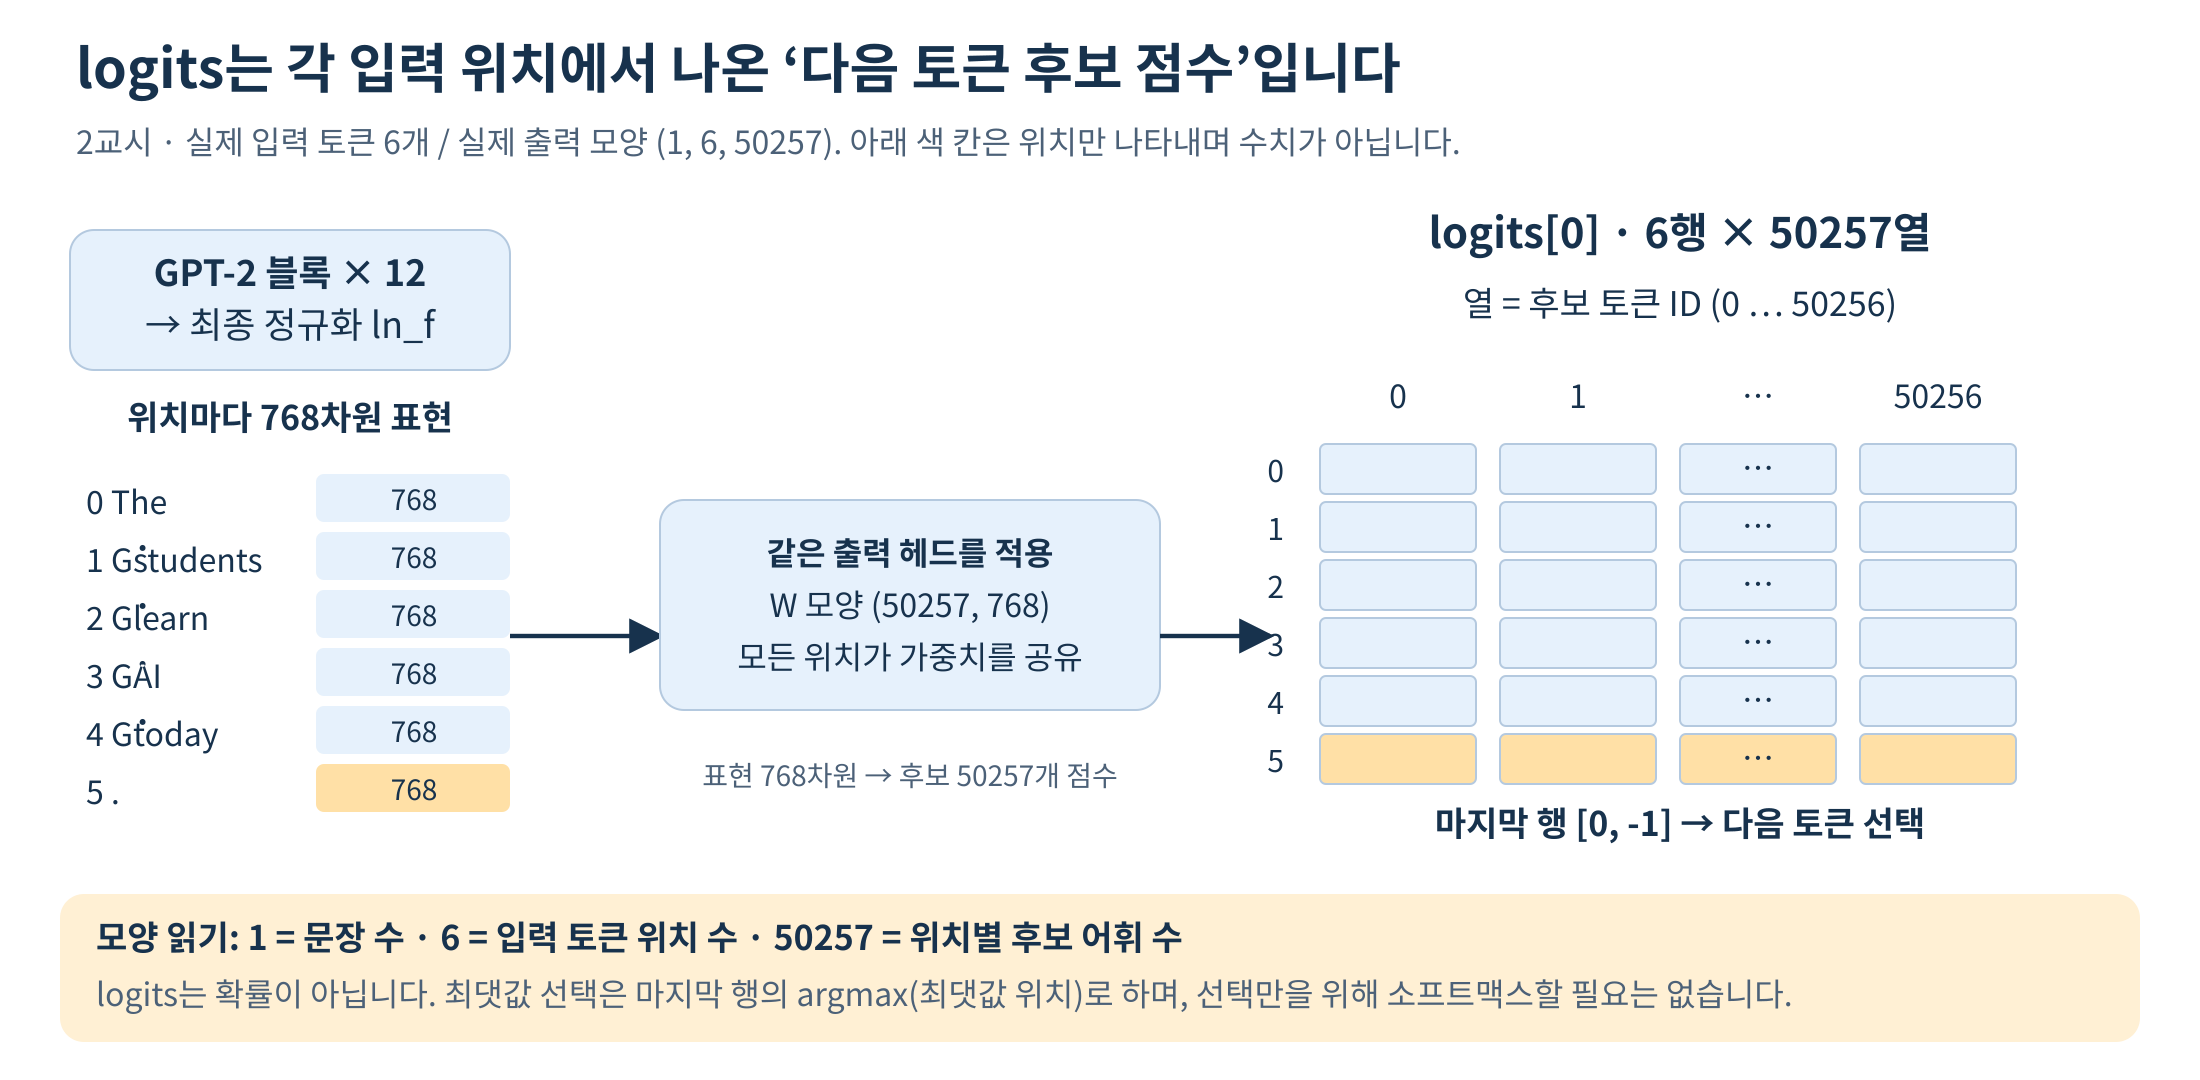

**그림 설명:** 입력 토큰과 (1, 6, 50257)은 실제 실행 기록에 따른 값입니다. 행렬의 색 칸은 위치를 보여 주는 개념 표시이며 점수 수치나 확률을 만들어 넣지 않았습니다.

**첫 층 어텐션의 크기 `(1, 12, 6, 6)`은 어떻게 나왔을까요?**

이 실행에서는 **문장 1개**를 넣었고 그 문장이 **토큰 6개**로 나뉘었습니다. 첫 번째 층에는 **어텐션 헤드(attention head) 12개**가 있습니다. 각 헤드는 입력의 6개 위치에서 쿼리(query, Q)와 키(key, K)를 하나씩 만듭니다.

헤드 하나에서 Q와 K는 각각 `(6, 64)`입니다. `Q @ K.T`를 계산하면 `(6, 64) × (64, 6) → (6, 6)`이 됩니다. **행은 읽는 위치, 열은 참고하는 위치**입니다. 미래 위치를 가리고 소프트맥스(softmax)로 가중치를 만들어도 표의 크기는 바뀌지 않습니다.

이 표가 헤드마다 하나씩 있으므로, 문장 1개에 대해 **`(1, 12, 6, 6)`**이 됩니다. 여기서 12는 **첫 번째 층 안의 헤드 수**입니다. 12개 층의 어텐션 결과는 별도로 반환됩니다. **로짓의 열은 어휘 후보 ID**, **어텐션의 열은 입력 토큰 위치**라는 차이도 기억하세요.


### 코드 설명: 한 문장을 12개 블록에 통과시키기

문장을 토큰화하여 전체 12개 블록에 한 번 통과시키는 순전파입니다. 위치별 어휘 점수와 층별 어텐션 가중치를 함께 관찰하되, 아직 토큰을 선택하여 입력에 붙이지 않습니다. 유효 입력 위치를 표시하는 attention_mask와 미래를 가리는 인과 마스크의 역할을 구분하세요.


In [24]:
prompt = "The students learn AI today."
# 문자열을 ID와 유효 위치 마스크의 묶음으로 만듭니다. 인과 마스크는 모델 내부에 별도로 적용됩니다.
inputs = tokenizer(prompt, return_tensors="pt")
# ID는 정수 주소이고 실수 표현 벡터가 아닙니다. 모델과 같은 장치로 옮깁니다.
input_ids = inputs["input_ids"].to(device)
# 입력의 유효한 칸을 표시합니다. 미래 토큰을 가리는 인과 제약은 모델에서 따로 적용됩니다.
attention_mask = inputs["attention_mask"].to(device)
# 두 번째 축은 입력 토큰 수입니다. 문자 수나 단어 수와 항상 같지는 않습니다.
T = input_ids.shape[1]
# 뒤의 위치 비교에 필요한 최소 길이와 모델이 지원하는 위치 범위를 확인합니다.
assert 2 <= T <= model.config.n_positions
print("입력 문장:", prompt)
print("입력 ID:", input_ids[0].tolist())
print("토큰 표시:", tokenizer.convert_ids_to_tokens(input_ids[0].tolist()))
print("입력 토큰 수:", T)
# 학습하지 않고 구조와 출력만 관찰하므로 기울기 기록을 끕니다.
with torch.inference_mode():
    # 전체 블록을 실행하고 각 층 어텐션도 반환합니다. 생성용 KV 캐시는 만들지 않습니다.
    original = model(input_ids, attention_mask=attention_mask,
                     output_attentions=True, use_cache=False)
print("logits shape:", tuple(original.logits.shape))
print("어텐션 층 수:", len(original.attentions))
print("첫 층 attention shape:", tuple(original.attentions[0].shape))
assert original.logits.shape == (1, T, 50257)
assert len(original.attentions) == 12
assert all(a.shape == (1, 12, T, T) for a in original.attentions)
print("[PASS] 실제 크기 GPT-2의 전체 12블록 forward")


입력 문장: The students learn AI today.
입력 ID: [464, 2444, 2193, 9552, 1909, 13]
토큰 표시: ['The', 'Ġstudents', 'Ġlearn', 'ĠAI', 'Ġtoday', '.']
입력 토큰 수: 6
logits shape: (1, 6, 50257)
어텐션 층 수: 12
첫 층 attention shape: (1, 12, 6, 6)
[PASS] 실제 크기 GPT-2의 전체 12블록 forward


### 출력 설명: 실행 기록과 확인 범위

- 이 문장은 6개 토큰으로 나뉘었습니다. `Ġ`는 화면에 표시한 내부 토큰에서 앞 공백을 나타내며, 문장에 실제로 입력한 특수 문자가 아닙니다. ID는 어휘 표의 번호이지 단어의 의미 크기가 아닙니다.
- logits의 `(1, 6, 50257)`은 **문장 1개 × 입력 위치 6개 × 어휘 후보 50,257개**입니다. 각 위치의 표현에서 다음 토큰 후보들의 점수를 낸 것이며, 아직 확률이나 선택된 답이 아닙니다.
- 첫 어텐션의 `(1, 12, 6, 6)`은 **문장 × 헤드 × 읽는 위치 × 참고 위치**입니다. PASS는 이런 모양이 12개 층 모두에서 확인되었다는 뜻입니다. 이 셀은 전체 모델을 통과시켰지만 새 토큰을 입력에 붙이지는 않았습니다.


## 5. 실제 어텐션 행렬에서 인과 마스크 찾기

**첫 행은 어떤 토큰인가요?** 이 입력의 첫 토큰은 `The`(ID `464`)입니다. 별도의 시작 토큰 `<BOS>`를 넣은 것이 아닙니다. 인과 마스크 때문에 첫 위치는 자기 자신만 참고할 수 있으므로, 첫 행은 자기 위치의 가중치가 1이고 나머지는 0입니다.

첫 번째 층의 첫 번째 헤드를 봅니다. 행은 **읽는 위치**, 열은 **참고하는 위치**입니다. 대각선 위쪽은 미래 위치이므로 가중치가 0입니다. 각 행의 합은 약 1입니다.

**실행 전 질문:** 첫 입력 토큰이 참고할 수 있는 위치는 몇 개인가요? **실행 후 확인:** 출력된 행렬을 앞의 ○/× 표와 연결하세요. 한 헤드의 큰 가중치 하나만으로 모델의 전체 판단 이유를 단정하지 않습니다. 어텐션은 모델 계산의 일부입니다.

### 개념 먼저: 행과 열을 문장 위치에 대응하기

어텐션 행렬에서 한 행을 고르면 그 위치가 어느 앞 위치를 참고하는지 볼 수 있습니다. 첫 토큰은 자기 앞에 다른 토큰이 없어 자신만 참고합니다. 뒤 위치는 참고 가능한 위치가 늘어나지만 인과 마스크 때문에 미래 위치는 계속 가려집니다.

인과 마스크는 참고해도 되는 위치를 정할 뿐, 허용된 위치를 똑같이 읽으라고 강제하지 않습니다. 가중치는 입력에 따라 달라지고 자기 위치에도 배분될 수 있습니다. 아래 표는 한 헤드의 사례이며, 코드는 모든 층·헤드에서 미래를 가렸는지와 허용 위치의 가중치 합을 검사합니다.


### 코드 설명: 인과적 어텐션을 행렬에서 찾기

화면에서는 첫 층·첫 헤드의 표를 읽고, 코드에서는 모든 층·헤드의 미래 위치와 행 합을 검사합니다. 행은 현재 읽는 위치, 열은 참고하는 위치입니다. 예를 들어 today 행과 마지막 마침표 열의 교차점은 아직 읽을 수 없는 미래이므로 0이어야 합니다. 표시용 반올림과 실제 수치 검사를 구분합니다.

**수치 비교 기준: 어텐션 행 합의 비교**

`allclose(a, b)`는 두 번째 인자 `b`를 기준으로 모든 성분에서 다음 조건을 검사합니다: $|a-b| \leq \mathrm{atol} + \mathrm{rtol}\,|b|$. `atol`은 절대 허용오차, `rtol`은 기준값 크기에 비례한 상대 허용오차입니다.

기준 `expected`의 모든 원소는 1이고 `atol=rtol=1e-5`이므로 각 행 합은 1과의 차이가 **0.00002 이하**이면 통과합니다. 표시용 세 자리 반올림 표가 아니라 원래 값의 합을 검사합니다. 미래 위치의 가중치는 별도의 `count_nonzero == 0`으로 **정확히 0인지** 검사하므로 두 기준을 혼동하지 않습니다.


In [25]:
# 표시용 첫 헤드와 전체 층·헤드를 검사하는 루프를 구분합니다.
first_head = original.attentions[0][0, 0].detach().cpu()
print("첫 층·첫 헤드 (행=읽는 위치, 열=참고 위치):")
# 세 자리 반올림은 화면 표시만 바꿉니다. 아래 검사는 원래 정밀도의 값으로 합니다.
print(first_head.round(decimals=3))
for layer_attention in original.attentions:
    # 대각선 위의 미래 위치 값이 모든 헤드에서 0인지 검사합니다.
    assert torch.count_nonzero(layer_attention.triu(1)).item() == 0
    # 마지막 축인 참고 위치별 가중치를 더하면 각 행의 합이 1이어야 합니다.
    expected = torch.ones_like(layer_attention.sum(-1))
    # 기준 b = expected; 원소별 허용 차이 = 1e-05 + 1e-05 × |b|.
    assert torch.allclose(layer_attention.sum(-1), expected, atol=1e-5, rtol=1e-5)
print("[PASS] 12층·12헤드의 미래 위치 가중치 0 / 행 합 1")


첫 층·첫 헤드 (행=읽는 위치, 열=참고 위치):
tensor([[1.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.7710, 0.2290, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.5700, 0.3370, 0.0930, 0.0000, 0.0000, 0.0000],
        [0.5630, 0.2440, 0.1080, 0.0850, 0.0000, 0.0000],
        [0.4940, 0.0850, 0.1520, 0.0700, 0.2000, 0.0000],
        [0.5890, 0.0660, 0.1470, 0.1060, 0.0700, 0.0220]])
[PASS] 12층·12헤드의 미래 위치 가중치 0 / 행 합 1


### 출력 설명: 실행 기록과 확인 범위

- 표의 행은 지금 계산하는 토큰 위치, 열은 그 행이 참고하는 입력 위치입니다. 둘째 행의 약 0.771과 0.229는 `students` 위치가 첫 위치와 자기 위치에 배분한 가중치입니다. 정답률이나 두 단어의 의미 유사도 점수가 아닙니다.
- 대각선 오른쪽이 모두 0이므로 아직 오지 않은 위치를 참고하지 않습니다. 첫 행은 참고 가능한 위치가 자신 하나라 가중치가 1입니다. 마지막 행은 여섯 위치 모두를 참고할 수 있습니다.
- 화면의 표는 첫 층·첫 헤드 한 개뿐이지만 PASS 검사는 12개 층의 모든 헤드를 대상으로 수행했습니다. 행 합은 반올림하기 전 값에서 허용오차 안에 1입니다. 표시된 세 자리 숫자를 손으로 더하면 반올림 때문에 약간 어긋날 수 있습니다.

**판정 기준 연결:** 이 셀의 비교는 `atol=1e-05, rtol=1e-05`를 사용합니다. 위 **코드 설명의 수치 비교 기준**에서 각 비교의 두 번째 인자와 실제 허용 차이 계산을 확인하세요. 출력의 최대 절대 차이와 `atol`만 비교하는 방식이 아니라, 각 기준값에 따른 `atol + rtol × |기준값|`으로 판정합니다.


## 6. 마지막 실제 입력 토큰만 바꾸기

입력의 마지막 문장부호만 바꾼 뒤, 각 위치에서 나온 다음 토큰 후보 점수를 원래 실행과 비교합니다.


### 개념 먼저: 한 조건만 바꾸는 대조 실험

마지막 문장부호만 바꾸고 앞부분과 길이는 유지합니다. 앞 위치의 출력까지 바뀌는지 관찰하면 인과적 정보 흐름을 점검할 수 있습니다. 문장 길이까지 바꾸면 위치 변화와 토큰 변화가 섞이므로 한 토큰 대체 여부를 먼저 확인합니다.

앞부분을 보존한 원문과 수정문은 같은 조건에서 모델을 통과합니다. 뒤의 변화가 앞 위치의 계산에 영향을 주지 않아야 인과적 구조와 맞습니다. 마지막 위치 자체는 토큰이 바뀌었으므로 점수가 달라지는 것이 자연스럽습니다. 아래 코드는 앞 위치의 유지와 마지막 위치의 변화를 서로 다른 판정으로 확인합니다.


### 코드 설명: 미래 토큰을 바꾸는 대조 실험

마지막 토큰만 교체하고 앞부분을 그대로 유지하는 대조 실험입니다. 앞 위치 점수는 유지되고 바뀐 위치의 점수는 달라지는지 비교하여 인과적 정보 흐름을 확인합니다. 한 입력의 구조 검사이며 모델의 언어 능력이나 정답률 평가가 아닙니다.

예를 들어 토큰이 여섯 개라면 마지막 여섯째 토큰만 바꿉니다. 두 번 실행한 뒤 앞의 다섯 위치와 마지막 위치를 따로 비교합니다. 앞 위치의 점수가 허용 오차 안에서 같으면, 마지막 토큰을 바꿔도 앞 위치의 계산값은 유지된다는 점을 이 예에서 확인할 수 있습니다.

**수치 비교 기준: 앞 위치 유지와 마지막 위치 변화의 기준**

`allclose(a, b)`는 두 번째 인자 `b`를 기준으로 모든 성분에서 다음 조건을 검사합니다: $|a-b| \leq \mathrm{atol} + \mathrm{rtol}\,|b|$. `atol`은 절대 허용오차, `rtol`은 기준값 크기에 비례한 상대 허용오차입니다.

앞 위치의 기준은 두 번째 인자인 **변경 후 점수**이고 `atol=rtol=1e-5`입니다. 가령 기준 점수의 절댓값이 10인 성분은 0.00011까지 허용합니다(계산 설명용 예). 따라서 출력하는 최대 절대 차이를 0.00001 하나와만 비교하면 안 됩니다. 반대로 `last_delta > 1e-5`는 **마지막 위치 점수 중 하나 이상이 0.00001보다 크게 바뀌었는지** 보는 별도의 절대 기준입니다. 이는 근사 일치 검사가 아니라 실제 변화가 있었는지 확인하는 검사입니다.


In [26]:
# 마지막 위치만 바꿀 수 있도록 대체 문자열이 한 토큰인지 먼저 검사합니다.
replacement = tokenizer.encode("!", add_special_tokens=False)
assert len(replacement) == 1, "대체 문자열이 한 토큰인지 확인하세요."
# 원본 입력을 보존한 채 마지막 위치만 바꾸어 비교 조건을 통제합니다.
changed_ids = input_ids.clone()
assert replacement[0] != changed_ids[0, -1].item()
changed_ids[0, -1] = replacement[0]
# 대조 실험에서 마지막 위치 이외의 조건이 바뀌지 않았는지 확인합니다.
assert torch.equal(changed_ids[:, :-1], input_ids[:, :-1])
print("변경한 문장:", tokenizer.decode(changed_ids[0].tolist()))
# 학습용 기울기를 기록하지 않고 현재 가중치로 계산합니다.
with torch.inference_mode():
    changed = model(changed_ids, attention_mask=attention_mask, use_cache=False)
# 바꾸지 않은 앞 위치 전체의 어휘 점수에서 가장 큰 절대 차이를 구합니다.
prefix_delta = (original.logits[:, :-1] - changed.logits[:, :-1]).abs().max().item()
# 바꾼 마지막 위치에서만 점수가 달라졌는지 별도로 확인합니다.
last_delta = (original.logits[:, -1] - changed.logits[:, -1]).abs().max().item()
print("앞 위치 logits 최대 차이:", prefix_delta)
print("마지막 위치 logits 최대 차이:", last_delta)
# 기준 b = changed.logits[:, :-1]; 원소별 허용 차이 = 1e-05 + 1e-05 × |b|.
assert torch.allclose(original.logits[:, :-1], changed.logits[:, :-1], atol=1e-5, rtol=1e-5)
# 마지막 위치의 변화 확인: 최대 절대 차이가 0.00001을 넘어야 합니다(일치 검사 아님).
assert last_delta > 1e-5
print("[PASS] 실제 GPT-2의 미래 토큰 변경 후 앞 위치 logits 유지")
print("[PASS] Lesson 02 실제 크기 모델 실습 완료")


변경한 문장: The students learn AI today!
앞 위치 logits 최대 차이: 0.0
마지막 위치 logits 최대 차이: 27.315902709960938
[PASS] 실제 GPT-2의 미래 토큰 변경 후 앞 위치 logits 유지
[PASS] Lesson 02 실제 크기 모델 실습 완료


### 출력 설명: 실행 기록과 확인 범위

- 마지막 마침표만 느낌표로 바꿨는데 앞 다섯 위치의 모든 어휘 점수에서 최대 차이가 0이었습니다. 앞 위치가 뒤의 토큰을 보지 못하는 인과적 구조와 일치하는 결과입니다.
- 마지막 위치에서는 최대 차이가 약 27.315903로 나타났습니다. 이는 바뀐 위치의 50,257개 점수 중 가장 크게 달라진 값의 절댓값이지, 확률 변화나 문장 전체의 품질 점수가 아닙니다.
- PASS는 앞 위치의 점수가 허용오차 내에서 같고 마지막 위치에는 변화가 있다는 두 조건을 확인합니다. 이 문장과 한 토큰 교체에 대한 검사이며, 모든 입력의 일반적 성능을 평가한 것은 아닙니다.

**판정 기준 연결:** 이 셀의 비교는 `atol=1e-05, rtol=1e-05`를 사용합니다. 위 **코드 설명의 수치 비교 기준**에서 각 비교의 두 번째 인자와 실제 허용 차이 계산을 확인하세요. 출력의 최대 절대 차이와 `atol`만 비교하는 방식이 아니라, 각 기준값에 따른 `atol + rtol × |기준값|`으로 판정합니다.


## 정리와 자기 점검
1. 실제 config의 `n_layer`와 `n_head`는 각각 무엇을 뜻하나요?

   **핵심 답과 이유:** `n_layer=12`는 Transformer 블록이 12개 쌓였다는 뜻입니다. `n_head=12`는 블록 하나의 셀프 어텐션에 헤드가 12개라는 뜻입니다.

2. 원래 Transformer 디코더의 크로스 어텐션은 무엇을 읽고, 기본 GPT-2에는 왜 그 정보 경로가 없나요?

   **핵심 답과 이유:** 원래 Transformer의 디코더는 자기 쪽 표현에서 쿼리(Q)를 만들고, 인코더 출력에서 만든 키(K)와 값(V)을 읽습니다. 기본 GPT-2에는 별도의 인코더가 없어 이 정보 경로가 없습니다. 입력 토큰끼리는 인과적 셀프 어텐션으로 정보를 주고받습니다.

3. 마지막 토큰을 바꾸어도 앞 위치의 점수가 유지되는 이유는 무엇인가요?

   **핵심 답과 이유:** 인과 마스크는 각 위치가 자기 위치와 그 앞까지만 보게 합니다. 예를 들어 `today` 위치는 그 뒤의 `.`이나 `!`를 보지 못합니다. 그래서 이 실행에서 앞 다섯 위치의 다음 토큰 점수 차이는 `0.0`이었습니다.

4. 입력을 짧게 만든 것과 모델 크기를 줄인 것은 어떻게 다른가요?

   **핵심 답과 이유:** 입력을 짧게 하면 처리할 토큰 위치 수가 줄고, 모델의 블록 수나 가중치는 그대로입니다. 모델 크기를 줄이는 것은 블록 수나 표현 차원 등을 줄인 다른 모델을 쓰는 일입니다.




Notebook을 저장하고 **Restart Kernel → Run All**로 다시 실행합니다. 다운로드된 파일은 캐시에서 재사용합니다. 마지막 PASS를 확인하고 저장합니다. 오류가 있으면 실패한 셀·커널 경로·오류 전문을 확인하고, 모델 크기를 줄이거나 CPU로 바꾸어 통과 처리하지 않습니다.

다음 교시에서는 표현이 어떻게 다음 토큰의 점수와 선택으로 이어지는지 더 자세히 다룹니다.

## 참고 자료
실습 모델은 `openai-community/gpt2`입니다. 아래 정보는 검증에 사용한 파일을 확인하기 위한 참고 자료입니다. 별도로 입력하거나 링크를 눌러 파일을 받을 필요는 없습니다.

- **고정 버전(커밋 ID):** `607a30d783dfa663caf39e06633721c8d4cfcd7e`
- [모델 카드](https://huggingface.co/openai-community/gpt2): 모델 소개와 저장소에 표시된 라이선스(MIT)
- [설정 파일](https://huggingface.co/openai-community/gpt2/blob/607a30d783dfa663caf39e06633721c8d4cfcd7e/config.json): 층 수, 헤드 수, 표현 차원 등 모델 구조
- [학습 가중치(safetensors)](https://huggingface.co/openai-community/gpt2/blob/607a30d783dfa663caf39e06633721c8d4cfcd7e/model.safetensors): 실습에서 불러오는 공식 가중치
- [GPT-2 구현 문서](https://huggingface.co/docs/transformers/model_doc/gpt2): 설정의 기본값과 모델 출력 형식